# Proyección del gasto público en pensiones

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "proyeccion-gasto-pensiones"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Proyección del gasto público en pensiones"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "proyeccion"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del PIB (proyección)"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El gasto público en pensiones, en porcentaje del PIB, que prevén para las próximas décadas las proyecciones oficiales que recoge la OCDE en *Pensions at a Glance 2025*. Para los países de la UE, como España, son las del *Ageing Report* de la Comisión Europea y el Comité de Política Económica; para Estados Unidos y Canadá, las de sus organismos nacionales.

**Cómo se lee.** Cada punto es lo que la proyección prevé para ese año (la OCDE publica un dato cada cinco años) si se cumplen sus hipótesis de población, empleo y productividad y se aplican las reformas aprobadas cuando se hizo. No es un dato observado ni una previsión de lo que ocurrirá con certeza.

**Limitaciones.**
- **Depende de las hipótesis:** natalidad, esperanza de vida, saldo migratorio, tasa de empleo y productividad. Cambios pequeños en ellas mueven mucho el gasto a décadas vista.
- **Fecha de las hipótesis:** las del *Ageing Report* de 2024 se fijaron en 2023 (proyecciones de población EUROPOP2023) y no incluyen la información posterior; la AIReF actualiza la de España con sus propios modelos (sección 3).
- **Reformas incluidas:** cada proyección incluye solo las reformas aprobadas antes de hacerse; la de España incluye las de 2021 y 2023.
- **Medias:** la OCDE publica la proyección de su media («OECD average country», media simple de los países con dato). No publica la de la UE-27: se calcula aquí como media simple de los 27 países, el mismo método que la media de la OCDE (METODOLOGIA §2.3, pendiente de aprobación humana). No es la media ponderada por el PIB que da el *Ageing Report* para la UE.
- **En la web** la gráfica usa la vista de proyección: todos sus años son proyectados (trazo de puntos), con la edición de cada proyección, y los principales resultados no los tratan como datos observados.

## 2. Descarga

- **España, EE. UU., Canadá, media de la OCDE (`OECD_REP`) y los 27 países de la UE:** OCDE, *Pensions at a Glance* (`OECD.ELS.SPD,DSD_PAG@DF_PAG,1.0`), medida `PPEP` (proyecciones del gasto público en pensiones), en % del PIB (`PT_B1GQ`).
- **Comprobación (no se publica como serie):** el gasto observado en pensiones de la misma base (`PEP`) y la última proyección de la AIReF para España, leída del texto de su *Estudio de evaluación de la regla de gasto de pensiones* (29-5-2026), que no publica los datos en un fichero.

In [ ]:
import re
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import airef, oecd
from lib.tipos import FuenteMeta

# PAG: REF_AREA.FREQ.MEASURE.UNIT_MEASURE.SEX.AGE.OPTIONALITY
DATAFLOW_PAG = "OECD.ELS.SPD,DSD_PAG@DF_PAG,1.0"
import json

AREAS = {"ESP": "espana", "USA": "eeuu", "CAN": "canada", "OECD_REP": "ocde", "EU27_2020": "ue27"}
PAISES = json.loads((RAIZ / "global.json").read_text(encoding="utf-8"))["paises"]
UE27 = [p["codigo"] for p in PAISES if "ue27" in p["grupos"]]
OCDE = [p["codigo"] for p in PAISES if "ocde" in p["grupos"]]
proy, fuentes_proy = oecd.get(DATAFLOW_PAG, "{AREA}.A.PPEP.PT_B1GQ._Z._Z._Z", areas=AREAS, desde=DESDE)
# Todos los países, para calcular la media de la UE-27 y contrastar el método con la media de la OCDE
paises, fuentes_paises = oecd.get(
    DATAFLOW_PAG, "{AREA}.A.PPEP.PT_B1GQ._Z._Z._Z", areas={c: c for c in dict.fromkeys(UE27 + OCDE)}, desde=DESDE
)
obs, _ = oecd.get(DATAFLOW_PAG, "{AREA}.A.PEP.PT_B1GQ._Z._Z._Z", areas={"ESP": "espana", "USA": "eeuu", "CAN": "canada"}, desde=DESDE)
texto_airef, fuente_airef = airef.get_texto(airef.ESTUDIO_REGLA_GASTO_2026)
print(proy.pivot(index="periodo", columns="serie", values="valor"))

Overwriting cache for 0 3894


serie    canada  eeuu  espana  ocde
periodo                            
2023        6.5   5.2    13.6   8.8
2025        7.2   5.3    13.7   9.0
2030        7.8   5.6    14.3   9.3
2035        8.0   5.8    15.4   9.5
2040        8.1   5.9    16.2   9.7
2045        8.1   5.9    16.9   9.9
2050        8.1   5.9    17.3  10.0
2055        8.1   6.0    17.2  10.1
2060        8.3   6.1    16.9  10.3


## 3. Transformación

La OCDE publica la proyección en % del PIB y la de su media (`OECD_REP`, «OECD average country»). La UE-27 es la media simple de los 27 países en cada año, solo si todos tienen dato; el método se contrasta calculando igual la media de los países de la OCDE y comparándola con la que publica la OCDE.

### Comprobaciones

1. El primer año de la proyección frente al gasto observado de la misma base (`PEP`).
2. La media simple de los países de la OCDE frente a la que publica la OCDE.
3. España: la proyección de la OCDE (*Ageing Report* de 2024) frente a la de la AIReF de 2026, con las cifras que da el texto de su estudio.

In [ ]:
assert "ue27" not in set(proy["serie"]), "la OCDE publica ya la proyección de la media de la UE-27: usarla"
assert "ocde" in set(proy["serie"]), "la OCDE ya no publica la proyección de su media (OECD_REP)"
HOY = fuentes_proy[0].fecha_consulta
tabla = paises.pivot(index="periodo", columns="serie", values="valor")
falta_ue = [c for c in UE27 if c not in tabla.columns]
assert not falta_ue, f"países de la UE sin proyección: {falta_ue}"
# Media simple de la UE-27, solo en los años con dato de los 27
ue27 = tabla[UE27].dropna().mean(axis=1).round(1)
# Contraste: la misma media simple con los países de la OCDE con dato en todos los años frente a OECD_REP
ocde_cal = tabla[[c for c in OCDE if c in tabla.columns]].dropna(axis=1).mean(axis=1)
ocde_pub = proy[proy["serie"] == "ocde"].set_index("periodo")["valor"]
contraste = pd.DataFrame({"media simple calculada": ocde_cal.round(2), "OECD_REP": ocde_pub})
display(contraste)
N_OCDE = tabla[[c for c in OCDE if c in tabla.columns]].dropna(axis=1).shape[1]
DIF_MAX = float((ocde_cal - ocde_pub).abs().max())
assert DIF_MAX < 0.3, "la media simple no reproduce la media publicada de la OCDE: revisar el método"
df = pd.concat([proy, pd.DataFrame({"serie": "ue27", "periodo": ue27.index, "valor": ue27.values})], ignore_index=True)
fuentes = [FuenteMeta(f.serie, f.organismo, "DSD_PAG@DF_PAG (PPEP, PT_B1GQ): proyección", f.url, f.fecha_consulta) for f in fuentes_proy]
fuentes += [FuenteMeta("ue27", oecd.ORGANISMO, "DSD_PAG@DF_PAG (PPEP, PT_B1GQ): media simple de los 27 países, cálculo propio", oecd.URL_EXPLORER, HOY)]

serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"]
PRIMER = int(proy["periodo"].min())

# Vista de proyección de la web: todos los años son proyectados, desde el primero que publica la OCDE.
# La OCDE toma la de España (y del resto de la UE) del Ageing Report 2024 y la de EE. UU. y Canadá de sus estimaciones.
EDICION = {
    "espana": "la Comisión Europea (Ageing Report 2024), que recoge la OCDE en Pensions at a Glance 2025",
    "ue27": "la Comisión Europea (Ageing Report 2024), que recoge la OCDE en Pensions at a Glance 2025 (media simple de los 27 países)",
    "ocde": "la OCDE (Pensions at a Glance 2025), media de los países de la OCDE",
    "eeuu": "la OCDE (Pensions at a Glance 2025), con estimaciones nacionales",
    "canada": "la OCDE (Pensions at a Glance 2025), con estimaciones nacionales",
}
PROYECCION = {s: {"desde": str(int(serie(df, s).index.min())), "edicion": e} for s, e in EDICION.items()}
assert set(PROYECCION) == set(df["serie"]), "series de la proyección sin edición"
comp_obs = pd.DataFrame({"proyección": proy[proy["periodo"] == PRIMER].set_index("serie")["valor"],
                         "observado (último)": obs.sort_values("periodo").groupby("serie")["valor"].last(),
                         "año observado": obs.groupby("serie")["periodo"].max()})
display(comp_obs)


def numero(x):
    return float(x.replace(",", "."))


m1 = re.search(r"desde el ([\d,]+) % del PIB en (\d{4}) hasta el ([\d,]+) % del PIB en (\d{4})", texto_airef)
m2 = re.search(r"aumentará del ([\d,]+) % al ([\d,]+) % del PIB entre (\d{4}) y (\d{4}) frente al ([\d,]+) % del Informe de Envejecimiento actualizado", texto_airef)
assert m1 and m2, "no se encuentran las cifras de la AIReF en el texto del estudio: revisar las expresiones"
AIREF_INI, AIREF_A_INI, AIREF_FIN, AIREF_A_FIN = numero(m1.group(1)), int(m1.group(2)), numero(m1.group(3)), int(m1.group(4))
AR_ACT_FIN = numero(m2.group(5))
assert numero(m2.group(2)) == AIREF_FIN and int(m2.group(4)) == AIREF_A_FIN
ES = serie(proy, "espana")
OCDE_FIN = ES.get(AIREF_A_FIN)
print(f"España {AIREF_A_FIN}: OCDE (Ageing Report 2024) {OCDE_FIN} · Ageing Report actualizado (según la AIReF) {AR_ACT_FIN} · AIReF {AIREF_FIN}")

,media simple calculada,OECD_REP
periodo,,
2023,8.82,8.8
2025,9.00,9.0
2030,9.27,9.3
2035,9.55,9.5
2040,9.71,9.7
2045,9.88,9.9
2050,10.02,10.0
2055,10.14,10.1
2060,10.29,10.3


,proyección,observado (último),año observado
serie,,,
canada,6.5,5.9,2021.0
eeuu,5.2,7.3,2021.0
espana,13.6,12.3,2021.0
ocde,8.8,NaN,NaN


España 2050: OCDE (Ageing Report 2024) 17.3 · Ageing Report actualizado (según la AIReF) 16.3 · AIReF 16.4


### Notas

In [ ]:
def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales).replace("-", "−")


anios = sorted(proy["periodo"].unique())
NOTAS = [
    "OCDE, Pensions at a Glance 2025 (DSD_PAG@DF_PAG), proyecciones del gasto público en "
    "pensiones en % del PIB (PPEP); para España y los demás países de la UE, las del Ageing Report de 2024 de la "
    f"Comisión Europea, y para EE. UU. y Canadá, estimaciones nacionales. La OCDE da un dato para {anios[0]} y cada cinco años de {anios[1]} a {anios[-1]}.",
    "Son proyecciones, no datos observados: dependen de las hipótesis de población, empleo y productividad y solo "
    "incluyen las reformas aprobadas antes de hacerse (en España, las de 2021 y 2023).",
    f"España según la AIReF (Estudio de evaluación de la regla de gasto de pensiones, 29-5-2026): el gasto bruto en "
    f"pensiones pasaría del {fmt(AIREF_INI)} % del PIB en {AIREF_A_INI} al {fmt(AIREF_FIN)} % en {AIREF_A_FIN}, frente "
    f"al {fmt(AR_ACT_FIN)} % del Ageing Report actualizado con los datos observados hasta 2025 y al {fmt(OCDE_FIN)} % "
    f"de la proyección original que recoge la OCDE. La AIReF usa sus propios modelos de población y un cuadro "
    f"macroeconómico de largo plazo; las hipótesis del Ageing Report se fijaron en 2023.",
    "Media OCDE: la que publica la OCDE («OECD average country»), media simple de los países con proyección.",
    f"Media UE-27: cálculo propio, media simple de las proyecciones de los 27 países de la UE (todos con dato), con el "
    f"mismo método que la media de la OCDE: calculada igual con los {N_OCDE} países de la OCDE con dato en todos los "
    f"años, difiere como mucho en {fmt(DIF_MAX, 2)} puntos de la que publica la OCDE. No es la media ponderada por el "
    "PIB que da el Ageing Report para el conjunto de la UE.",
    "Cada proyección tiene su propia cobertura del gasto y no siempre coincide con el gasto observado de la misma "
    "base (PEP): " + "; ".join(
        f"{n}, {fmt(comp_obs.loc[s, 'proyección'])} % en {PRIMER} en la proyección frente a "
        f"{fmt(comp_obs.loc[s, 'observado (último)'])} % observado en {int(comp_obs.loc[s, 'año observado'])}"
        for s, n in (("espana", "España"), ("eeuu", "EE. UU."), ("canada", "Canadá"))
    ) + ".",
]
for n in NOTAS:
    print("-", n)

- OCDE, Pensions at a Glance 2025 (DSD_PAG@DF_PAG), proyecciones del gasto público en pensiones en % del PIB (PPEP); para España y los demás países de la UE, las del Ageing Report de 2024 de la Comisión Europea, y para EE. UU. y Canadá, estimaciones nacionales. La OCDE da un dato para 2023 y cada cinco años de 2025 a 2060.
- Son proyecciones, no datos observados: dependen de las hipótesis de población, empleo y productividad y solo incluyen las reformas aprobadas antes de hacerse (en España, las de 2021 y 2023).
- España según la AIReF (Estudio de evaluación de la regla de gasto de pensiones, 29-5-2026): el gasto bruto en pensiones pasaría del 12,7 % del PIB en 2022 al 16,4 % en 2050, frente al 16,3 % del Ageing Report actualizado con los datos observados hasta 2025 y al 17,3 % de la proyección original que recoge la OCDE. La AIReF usa sus propios modelos de población y un cuadro macroeconómico de largo plazo; las hipótesis del Ageing Report se fijaron en 2023.
- Media OCDE: la que pub

## 4. Visualización

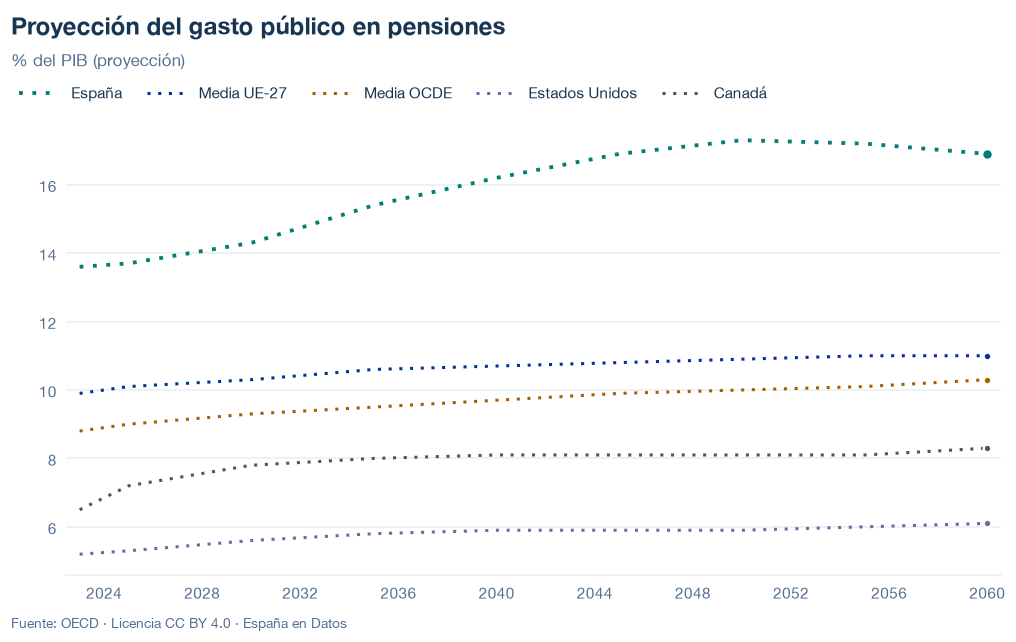

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    proyeccion=PROYECCION,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema, con `proyeccion`) y `data/<id>.csv`.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    proyeccion=PROYECCION, path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/proyeccion-gasto-pensiones.json y data/proyeccion-gasto-pensiones.csv


## 6. Fuentes, notas y licencia

- OCDE, *Pensions at a Glance* (`OECD.ELS.SPD,DSD_PAG@DF_PAG,1.0`): `PPEP` (serie de la gráfica, con la media de la OCDE `OECD_REP` y los 27 países de la UE para la media de la UE-27) y `PEP` (comprobación).
- AIReF, *Estudio de evaluación de la regla de gasto de pensiones* (29-5-2026), texto del PDF, para las notas.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.